# The Fitting Room: backtesting the size recommender

This notebook tests whether the recommender's probabilities hold up on real shoppers it has never seen.

**Question.** If a shopper tells us the size of a pair they own and how it fits, how well can we predict the size that fits their next pair, and is the confidence we show them honest?

**Data.** ModCloth clothing fit dataset (Misra, Wan and McAuley, 2018). Only bottoms are used. Shoppers who bought more than one pair give us natural experiments: one purchase plays the pair they own, the other plays the pair they want next.

**Method.** Five fold cross validation, split by shopper, so no shopper is used for both learning and testing. Three models are compared:

* **Same size again**: always recommend the owned size, with full certainty.
* **001 assumed model**: the prior and sensor tables the 001 prototype shipped with, set by hand.
* **Learned model**: the same Bayesian structure, with both tables estimated from the training shoppers.

In [1]:
import os, sys, json, subprocess, urllib.request
from pathlib import Path

# In Google Colab, fetch the project code first.
if not Path('backtest.py').exists():
    if not Path('the-fitting-room').exists():
        subprocess.run(['git', 'clone', '--depth', '1', 'https://github.com/joellesteiner/the-fitting-room'], check=True)
    os.chdir('the-fitting-room/research/backtest')
sys.path.insert(0, '.')

# ModCloth dataset (Misra, Wan and McAuley, 2018). Tries the authors' host, then a public mirror.
# If both fail, upload modcloth_final_data.json into this folder and rerun.
import gzip, shutil
DATA = Path('modcloth_final_data.json')
SOURCES = ['https://datarepo.eng.ucsd.edu/mcauley_group/data/modcloth/modcloth_final_data.json.gz',
           'https://media.githubusercontent.com/media/hkbuttar/Machine-Learning-Final-Project/HEAD/Data/Raw/modcloth_final_data.json']
for url in SOURCES:
    if DATA.exists():
        break
    try:
        tmp, _ = urllib.request.urlretrieve(url)
        if url.endswith('.gz'):
            with gzip.open(tmp, 'rb') as src, open(DATA, 'wb') as dst:
                shutil.copyfileobj(src, dst)
        else:
            shutil.copy(tmp, DATA)
    except Exception as e:
        print('could not fetch', url, e)
print(DATA, round(DATA.stat().st_size / 1e6, 1), 'MB')

modcloth_final_data.json 40.6 MB


## 1. Build the examples

In [2]:
import fitdata, model, backtest
import pandas as pd

raw = fitdata.load_bottoms(DATA)
scale = fitdata.size_scale(raw)
ranked = fitdata.add_rank(raw, scale)
pairs = fitdata.make_pairs(ranked)
print(f'{len(raw):,} bottoms purchases with a fit label')
print(f'size scale used: {scale}')
print(f"{pairs['user_id'].nunique():,} repeat shoppers give {len(pairs):,} owned and next pair examples")
pairs['report_b'].value_counts(normalize=True).round(3)

15,266 bottoms purchases with a fit label
size scale used: [1, 4, 6, 8, 10, 12, 14, 15, 17, 20, 26, 32, 38]
2,213 repeat shoppers give 8,774 owned and next pair examples


report_b
right    0.727
tight    0.153
loose    0.120
Name: proportion, dtype: float64

Most next pairs are reported as right (about 70%). That imbalance matters: any model can look accurate by always predicting "right", so accuracy alone is not used to judge the fit predictions.

## 2. Run the backtest

In [3]:
results = backtest.run(DATA, folds=5)

def table(section):
    rows = {name: {k: f"{v['mean']:.3f} ± {v['sd']:.3f}" for k, v in metrics.items()} for name, metrics in results[section].items()}
    return pd.DataFrame(rows).T

table('size')[['exact', 'within1', 'mean_conf', 'ece', 'log_loss']]

15266 bottoms rows, 14981 on the size scale [1, 4, 6, 8, 10, 12, 14, 15, 17, 20, 26, 32, 38]
2213 repeat shoppers, 8774 owned and next pairs
fold 1/5 done
fold 2/5 done


fold 3/5 done
fold 4/5 done
fold 5/5 done


,exact,within1,mean_conf,ece,log_loss
Same size again,0.509 ± 0.014,0.735 ± 0.008,1.000 ± 0.000,0.491 ± 0.014,13.572 ± 0.383
001 assumed model,0.452 ± 0.020,0.735 ± 0.011,0.582 ± 0.001,0.130 ± 0.019,3.305 ± 0.177
Learned model,0.509 ± 0.014,0.735 ± 0.008,0.516 ± 0.004,0.031 ± 0.012,2.572 ± 0.147


**Reading the size results** (pairs where the next pair fitted, so the right size is known):

* The learned model matches **Same size again** on accuracy (about 51% exact, 74% within one size) but replaces false certainty with honest confidence: calibration error drops from 49% to about 3%.
* The 001 assumed model is **less accurate** (about 45% exact). Its rule that a tight pair means size up does not hold across ModCloth's brands, and its confidence is off by about 13 points on average.
* Lower log loss means the true size received more probability. The learned model is best on this measure.

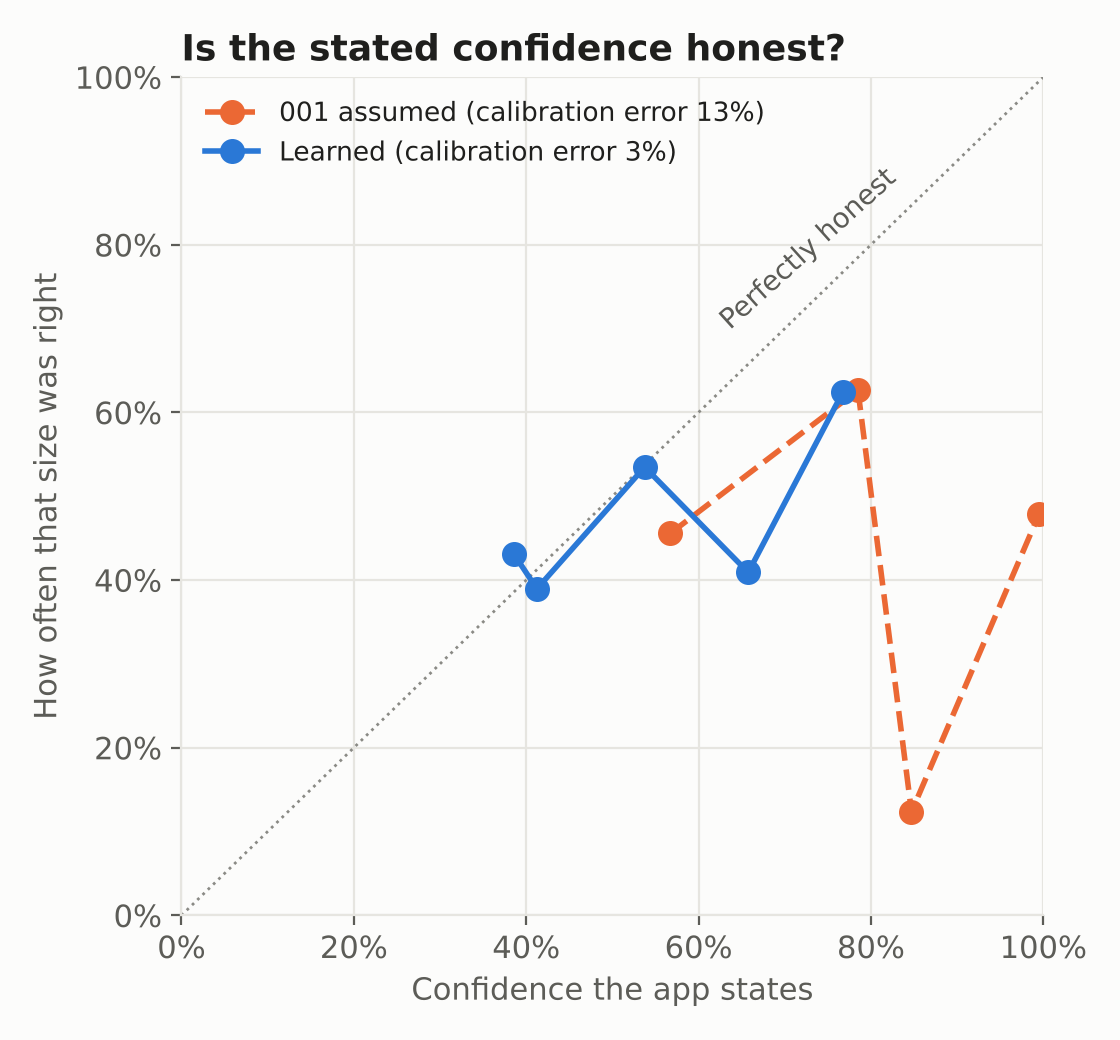

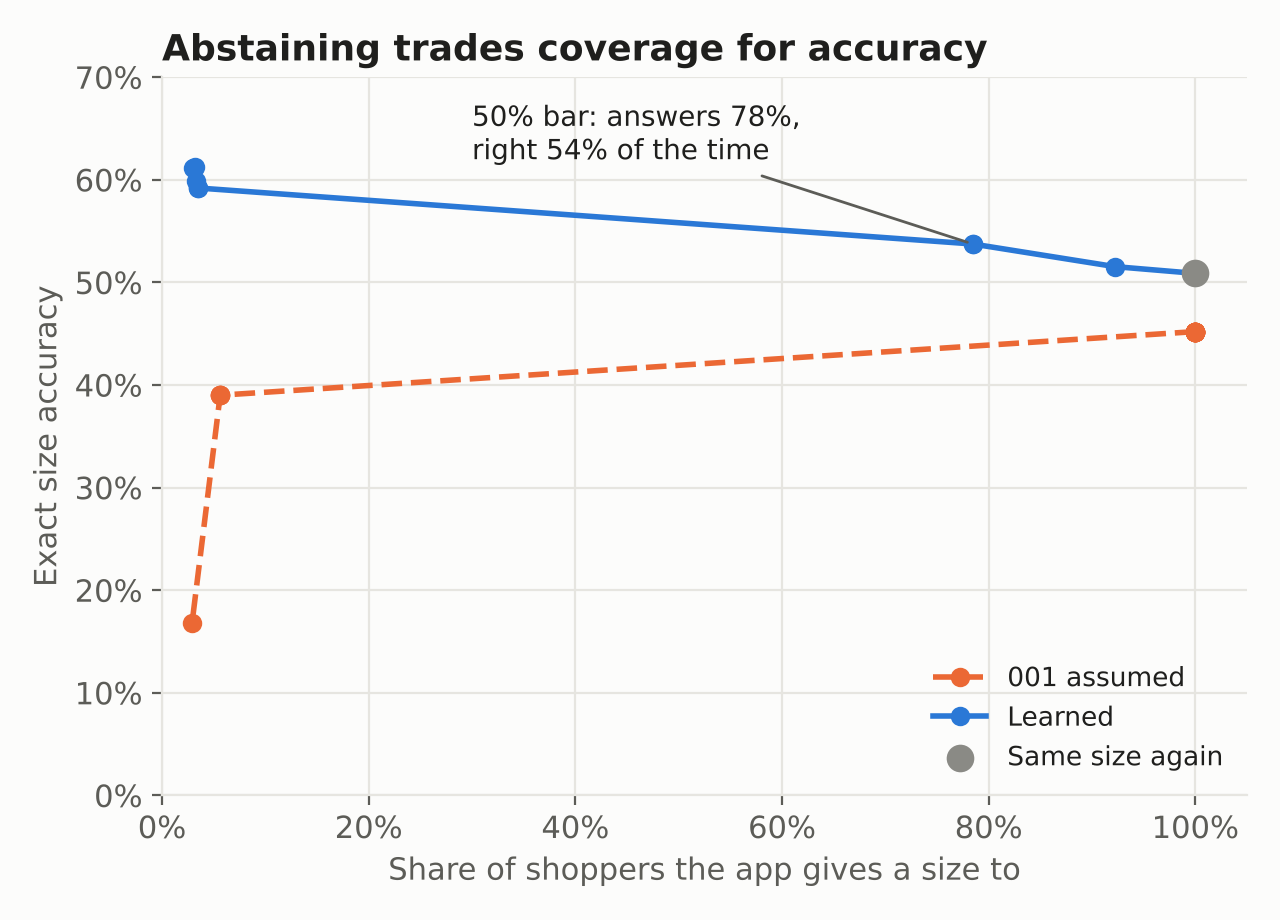

In [4]:
from IPython.display import Image, display
import charts
charts.sensor_chart(results); charts.calibration_chart(results); charts.coverage_chart(results)
for name in ('calibration.png', 'coverage_vs_accuracy.png'):
    display(Image(filename=f'results/{name}'))

**Abstention works as designed.** With the learned model, refusing to answer below the 50% confidence bar keeps 78% of shoppers and raises exact accuracy from 51% to 54%. Raising the bar further buys more accuracy for far fewer shoppers. The 001 model cannot do this usefully, because its confidence does not track how often it is right.

## 3. The sensor model: assumed against learned

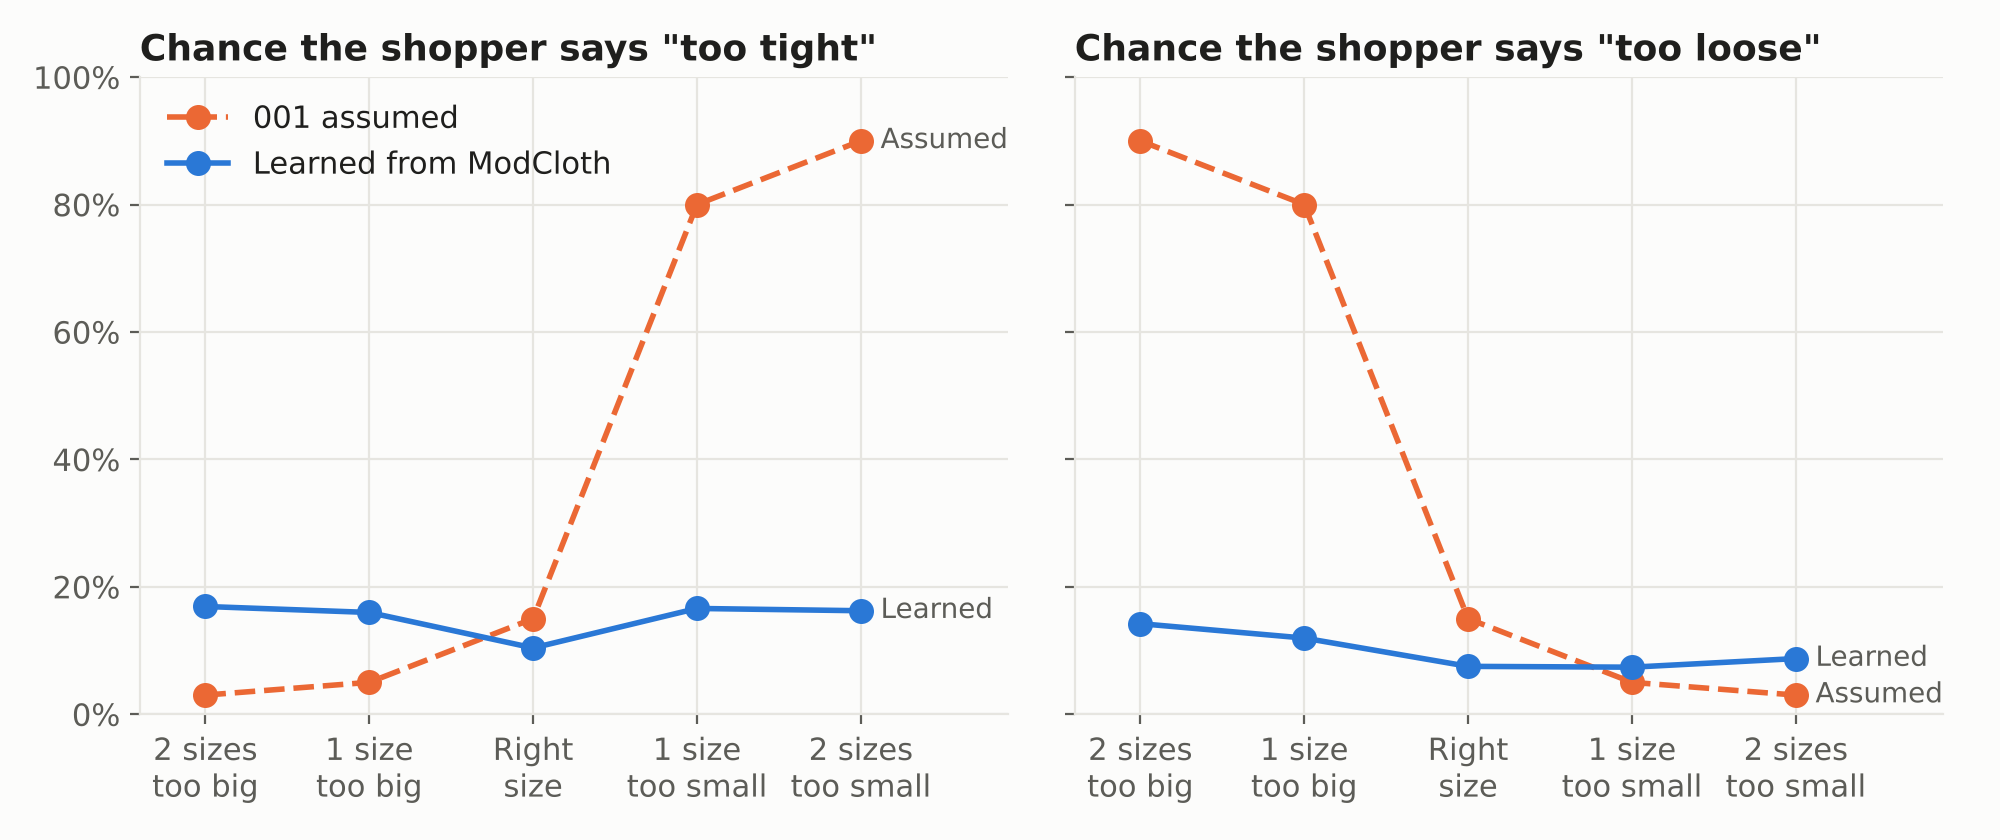

,tight,right,loose
true minus worn size,,,
-2,0.1691,0.6888,0.1421
-1,0.1597,0.7208,0.1195
0,0.1040,0.8209,0.0751
1,0.1660,0.7603,0.0738
2,0.1624,0.7503,0.0873


In [5]:
display(Image(filename='results/sensor_assumed_vs_learned.png'))
pd.DataFrame(results['learned_sensor']).T.rename_axis('true minus worn size')

This is the most important finding. The 001 prototype assumed that a shopper wearing one size too small says "too tight" 80% of the time. On ModCloth, the learned figure is about 17%, barely above the 10% seen at the right size.

The direction is correct, but the signal is weak. The likely cause is that ModCloth sells many brands with inconsistent sizing, so a shopper's size in one brand says little about their size in another. That supports the product's design choice to anchor on a pair from the **same brand**, and tells the pilot what data it must collect: fit reports linked to specific garments within one brand's range.

## 4. Predicting the fit report

In [6]:
table('fit')[['log_loss', 'brier', 'macro_recall', 'recall_tight', 'recall_loose']]

,log_loss,brier,macro_recall,recall_tight,recall_loose
Class frequency baseline,0.774 ± 0.022,0.434 ± 0.015,0.333 ± 0.000,0.000 ± 0.000,0.000 ± 0.000
001 assumed model,1.390 ± 0.028,0.867 ± 0.017,0.436 ± 0.021,0.398 ± 0.022,0.457 ± 0.034
"Learned prior, assumed sensor",1.342 ± 0.020,0.841 ± 0.013,0.408 ± 0.019,0.290 ± 0.030,0.475 ± 0.026
Learned model,0.772 ± 0.024,0.433 ± 0.016,0.333 ± 0.000,0.000 ± 0.000,0.000 ± 0.000


* The 001 assumed model is badly overconfident: its log loss (1.39) is far worse than simply quoting the base rates (0.77).
* Swapping in the learned prior alone barely helps; swapping in the learned sensor brings log loss down to the base rate level. In other words, almost all of the 001 model's error came from the invented sensor table.
* The 001 model does flag more poor fits (macro recall 0.44 against 0.33), but only by being confidently wrong most of the time, which is what the log loss captures.
* The learned model never predicts tight or loose as most likely, because on this data the owned pair is not informative enough to overturn a 70% base rate. Honest, but it shows the limit of cross brand data.

## 5. What changes as a result

1. The app now loads the learned sensor table instead of the hand set one (`app/model/sensor_learned.json`).
2. Fit reports after delivery move the belief less than before, so the app abstains more often. That is the correct response to weak evidence.
3. Same brand, garment linked fit data becomes the first requirement for the pilot.

## Limitations

* ModCloth has no purchase dates, so both orders of each pair are used.
* ModCloth size codes are mapped to an ordered scale; one step is treated as one size, which is approximate.
* Shoppers' own reports are noisy labels; some "right" reports will be tolerance rather than true fit.
* Results are for women's bottoms on one retailer and may not transfer to men's jeans or other retailers.

In [7]:
json.dumps(results['data'], indent=1)

'{\n "bottoms_rows": 15266,\n "rows_on_scale": 14981,\n "size_scale": [\n  1,\n  4,\n  6,\n  8,\n  10,\n  12,\n  14,\n  15,\n  17,\n  20,\n  26,\n  32,\n  38\n ],\n "repeat_shoppers": 2213,\n "pairs": 8774,\n "pairs_next_fitted": 6381,\n "folds": 5\n}'